In [1]:
# !pip install numpy matplotlib
import numpy as np
import time
import sys
import matplotlib.pyplot as plt

print("NumPy version:", np.__version__)

NumPy version: 2.4.4


# Part 1: NumPy Fundamentals

## 1.1 Creating arrays

In [2]:
# Example 1: array from a Python list
a = np.array([1, 2, 3, 4, 5])
print(a, "| dtype:", a.dtype, "| shape:", a.shape)

[1 2 3 4 5] | dtype: int64 | shape: (5,)


In [3]:
# Example 2: zeros and ones
print(np.zeros(5))
print(np.ones((2, 3)))

[0. 0. 0. 0. 0.]
[[1. 1. 1.]
 [1. 1. 1.]]


In [4]:
# Example 3: arange (like range, but returns an array)
print(np.arange(0, 10, 2))      # start, stop (excluded), step

[0 2 4 6 8]


In [5]:
# Example 4: linspace (N evenly spaced points, stop INCLUDED)
print(np.linspace(0, 1, 5))

[0.   0.25 0.5  0.75 1.  ]


In [6]:
# Example 5: other handy creators
print(np.full((2, 2), 7))       # filled with 7
print(np.eye(3))                # identity matrix

[[7 7]
 [7 7]]
[[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]


In [7]:
# Example 6: random arrays (seed makes results repeatable)
rng = np.random.default_rng(42)
print(rng.integers(1, 100, size=5))
print(rng.random(3))

[ 9 77 65 44 43]
[0.69736803 0.09417735 0.97562235]


## 1.2 Indexing and slicing

In [8]:
arr = np.array([10, 20, 30, 40, 50, 60])

# Example 7: single element and negative index
print(arr[0], arr[-1])

10 60


In [9]:
# Example 8: slicing [start:stop:step]
print(arr[1:4])
print(arr[::2])
print(arr[::-1])    # reversed

[20 30 40]
[10 30 50]
[60 50 40 30 20 10]


In [10]:
m = np.arange(1, 13).reshape(3, 4)
print(m)

# Example 9: 2D indexing [row, col]
print("m[1, 2] =", m[1, 2])

[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]]
m[1, 2] = 7


In [11]:
# Example 10: row / column / sub-matrix slicing
print("Row 0     :", m[0])
print("Column 1  :", m[:, 1])
print("Sub-matrix:\n", m[0:2, 1:3])

Row 0     : [1 2 3 4]
Column 1  : [ 2  6 10]
Sub-matrix:
 [[2 3]
 [6 7]]


## 1.3 Reshaping

In [12]:
x = np.arange(12)

# Example 11: reshape (total elements must match)
print(x.reshape(3, 4))
print(x.reshape(2, -1))     # -1 means "figure it out"

[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
[[ 0  1  2  3  4  5]
 [ 6  7  8  9 10 11]]


In [13]:
# Example 12: flatten, transpose, add an axis
grid = x.reshape(3, 4)
print("flatten  :", grid.flatten())
print("transpose:", grid.T.shape)
print("new axis :", x[:, np.newaxis].shape)

flatten  : [ 0  1  2  3  4  5  6  7  8  9 10 11]
transpose: (4, 3)
new axis : (12, 1)


## 1.4 Broadcasting

Broadcasting lets NumPy combine arrays of different shapes **without loops**.
Rule: compare shapes from the right; dimensions match if they are equal or one of them is 1.

In [14]:
# Example 13: scalar broadcast
print(np.array([1, 2, 3]) * 10)

[10 20 30]


In [15]:
# Example 14: row vector added to every row of a matrix
matrix = np.array([[1, 2, 3],
                   [4, 5, 6]])
row = np.array([10, 20, 30])
print(matrix + row)

[[11 22 33]
 [14 25 36]]


In [16]:
# Example 15: column vector (3,1) + row vector (1,3) -> full (3,3) table
col = np.array([[1], [2], [3]])
row = np.array([[10, 20, 30]])
print(col + row)

[[11 21 31]
 [12 22 32]
 [13 23 33]]


# Part 2: Array Operations

## 2.1 Element-wise operations

In [17]:
a = np.array([1, 2, 3, 4])
b = np.array([10, 20, 30, 40])

# Example 16: arithmetic works element by element
print("a + b :", a + b)
print("a * b :", a * b)
print("b / a :", b / a)
print("a ** 2:", a ** 2)

a + b : [11 22 33 44]
a * b : [ 10  40  90 160]
b / a : [10. 10. 10. 10.]
a ** 2: [ 1  4  9 16]


In [18]:
# Example 17: comparison gives a boolean array
print(a > 2)
print(a == b)

[False False  True  True]
[False False False False]


## 2.2 Mathematical functions

In [19]:
v = np.array([1, 4, 9, 16])

# Example 18: sqrt, exp, log
print(np.sqrt(v))
print(np.exp([0, 1, 2]))
print(np.log(v))

[1. 2. 3. 4.]
[1.         2.71828183 7.3890561 ]
[0.         1.38629436 2.19722458 2.77258872]


In [20]:
# Example 19: trigonometry and rounding
angles = np.array([0, np.pi / 2, np.pi])
print(np.sin(angles).round(2))
print(np.round([1.234, 5.678], 1), np.floor(2.7), np.ceil(2.1))

[0. 1. 0.]
[1.2 5.7] 2.0 3.0


In [21]:
# Example 20: cumulative sum / product and differences
n = np.array([1, 2, 3, 4, 5])
print(np.cumsum(n))
print(np.cumprod(n))
print(np.diff([1, 4, 9, 16]))

[ 1  3  6 10 15]
[  1   2   6  24 120]
[3 5 7]


## 2.3 Statistical functions

In [22]:
scores = np.array([55, 62, 70, 70, 78, 85, 90, 95, 99, 100])

# Example 21: mean, median, std, variance
print("mean  :", scores.mean())
print("median:", np.median(scores))
print("std   :", round(scores.std(), 2))
print("var   :", round(scores.var(), 2))

mean  : 80.4
median: 81.5
std   : 15.04
var   : 226.24


In [23]:
# Example 22: min, max, range, argmin/argmax
print("min/max :", scores.min(), scores.max())
print("range   :", np.ptp(scores))
print("where is max:", scores.argmax())

min/max : 55 100
range   : 45
where is max: 9


In [24]:
# Example 23: percentiles and quartiles
print("25th, 50th, 75th:", np.percentile(scores, [25, 50, 75]))

25th, 50th, 75th: [70.   81.5  93.75]


In [25]:
# Example 24: statistics along an axis (rows vs columns)
data = np.array([[1, 2, 3],
                 [4, 5, 6],
                 [7, 8, 9]])
print("column means (axis=0):", data.mean(axis=0))
print("row sums     (axis=1):", data.sum(axis=1))

column means (axis=0): [4. 5. 6.]
row sums     (axis=1): [ 6 15 24]


In [26]:
# Example 25: correlation between two variables
hours  = np.array([1, 2, 3, 4, 5, 6])
result = np.array([50, 55, 65, 70, 80, 85])
print("correlation:", round(np.corrcoef(hours, result)[0, 1], 3))

correlation: 0.995


## 2.4 Sorting and searching

In [27]:
nums = np.array([42, 7, 19, 3, 88, 19])

# Example 26: sort and argsort
print("sorted  :", np.sort(nums))
print("argsort :", np.argsort(nums))     # indices that would sort the array
print("descending:", np.sort(nums)[::-1])

sorted  : [ 3  7 19 19 42 88]
argsort : [3 1 2 5 0 4]
descending: [88 42 19 19  7  3]


In [28]:
# Example 27: searching - where is a value?
print("indices of 19:", np.where(nums == 19)[0])

indices of 19: [2 5]


In [29]:
# Example 28: searchsorted (binary search in a SORTED array)
sorted_nums = np.sort(nums)
print("insert 20 at position:", np.searchsorted(sorted_nums, 20))

insert 20 at position: 4


## 2.5 Unique values and counts

In [30]:
colors = np.array(["red", "blue", "red", "green", "blue", "red"])

# Example 29: unique values with counts
values, counts = np.unique(colors, return_counts=True)
for v, c in zip(values, counts):
    print(v, "->", c)

blue

 -> 2
green -> 1
red -> 3


In [31]:
# Example 30: most common value
print("most common:", values[counts.argmax()])

most common: red


# Part 3: Boolean Indexing and Filtering

In [32]:
ages = np.array([12, 25, 17, 40, 33, 8, 61, 19])

# Example 31: boolean mask
mask = ages >= 18
print("mask  :", mask)
print("adults:", ages[mask])

mask  : [False  True False  True  True False  True  True]
adults: [25 40 33 61 19]


In [33]:
# Example 32: combine conditions with & (and), | (or), ~ (not)
# Parentheses are required!
print("18 to 40  :", ages[(ages >= 18) & (ages <= 40)])
print("<18 or >60:", ages[(ages < 18) | (ages > 60)])
print("not adult :", ages[~(ages >= 18)])

18 to 40  : [25 40 33 19]
<18 or >60: [12 17  8 61]
not adult : [12 17  8]


In [34]:
# Example 33: count and check with masks
print("how many adults:", (ages >= 18).sum())
print("any over 60    :", (ages > 60).any())
print("all over 5     :", (ages > 5).all())

how many adults: 5
any over 60    : True
all over 5     : True


In [35]:
# Example 34: modify values using a mask
temp = ages.copy()
temp[temp < 18] = 18        # set minimum age to 18
print(temp)

[18 25 18 40 33 18 61 19]


In [36]:
# Example 35: np.where(condition, if_true, if_false)
labels = np.where(ages >= 18, "adult", "minor")
print(labels)

['minor' 'adult' 'minor' 'adult' 'adult' 'minor' 'adult' 'adult']


In [37]:
# Example 36: nested np.where for 3 categories
grade = np.array([95, 82, 67, 45])
result = np.where(grade >= 90, "A",
          np.where(grade >= 60, "B", "C"))
print(result)

['A' 'B' 'B' 'C']

In [38]:
# Example 37: fancy indexing (pick elements by a list of indices)
data = np.array([100, 200, 300, 400, 500])
print(data[[0, 2, 4]])
print(data[[4, 0, 0]])      # repeats and any order are allowed

[100 300 500]
[500 100 100]


In [39]:
# Example 38: fancy indexing on 2D arrays
m = np.arange(1, 17).reshape(4, 4)
print("rows 0 and 2:\n", m[[0, 2]])
print("diagonal:", m[[0, 1, 2, 3], [0, 1, 2, 3]])

rows 0 and 2:
 [[ 1  2  3  4]
 [ 9 10 11 12]]
diagonal: [ 1  6 11 16]


In [40]:
# Example 39: filter rows of a 2D array by a column condition
people = np.array([[25, 50000],
                   [32, 64000],
                   [47, 90000],
                   [29, 48000]])     # columns: age, salary
print(people[people[:, 1] > 55000])

[[   32 64000]
 [   47 90000]]


# Part 4: Performance and Vectorization


In [41]:
# Helper to time a function (takes the best of a few runs)
def timeit(func, runs=3):
    best = float("inf")
    for _ in range(runs):
        start = time.perf_counter()
        func()
        best = min(best, time.perf_counter() - start)
    return best

In [42]:
# Example 40: sum of squares - Python loop vs NumPy
N = 1_000_000
py_list = list(range(N))
np_arr = np.arange(N)

def loop_version():
    total = 0
    for x in py_list:
        total += x * x
    return total

def numpy_version():
    return (np_arr ** 2).sum()

t_loop, t_np = timeit(loop_version), timeit(numpy_version)
print(f"Loop : {t_loop:.4f} s")
print(f"NumPy: {t_np:.4f} s")
print(f"NumPy is about {t_loop / t_np:.0f}x faster")

Loop : 0.0582 s
NumPy: 0.0018 s
NumPy is about 32x faster


In [43]:
# Example 41: element-wise add - list comprehension vs NumPy
a_list, b_list = list(range(N)), list(range(N))
a_np, b_np = np.arange(N), np.arange(N)

t_list = timeit(lambda: [x + y for x, y in zip(a_list, b_list)])
t_np2  = timeit(lambda: a_np + b_np)
print(f"List : {t_list:.4f} s | NumPy: {t_np2:.5f} s | speedup: {t_list / t_np2:.0f}x")

List : 0.0512 s | NumPy: 0.00117 s | speedup: 44x


In [44]:
# Example 42: conditional logic - loop with if vs np.where
values = np.random.default_rng(0).integers(0, 100, N)
values_list = values.tolist()

def loop_cond():
    return [1 if v > 50 else 0 for v in values_list]

t_a = timeit(loop_cond)
t_b = timeit(lambda: np.where(values > 50, 1, 0))
print(f"Loop: {t_a:.4f} s | np.where: {t_b:.5f} s | speedup: {t_a / t_b:.0f}x")

Loop: 0.0307 s | np.where: 0.00709 s | speedup: 4x


### Memory efficiency

In [45]:
# Example 43: memory used by a list vs an array of 1 million ints
list_bytes = sys.getsizeof(py_list) + sum(sys.getsizeof(x) for x in py_list)
print(f"Python list: {list_bytes / 1e6:.1f} MB")
print(f"NumPy array: {np_arr.nbytes / 1e6:.1f} MB")

Python list: 36.0 MB
NumPy array: 8.0 MB


In [46]:
# Example 44: choosing a smaller dtype saves memory
big   = np.arange(1_000_000, dtype=np.int64)
small = np.zeros(1_000_000, dtype=np.int8)
print("int64:", big.nbytes / 1e6, "MB")
print("int8 :", small.nbytes / 1e6, "MB")
print("float32 vs float64:",
      np.ones(1000, dtype=np.float32).nbytes, "vs",
      np.ones(1000, dtype=np.float64).nbytes, "bytes")

int64: 8.0 MB
int8 : 1.0 MB
float32 vs float64: 4000 vs 8000 bytes


In [47]:
# Example 45: views vs copies (slices are views = no extra memory)
orig = np.arange(5)
view = orig[1:4]
view[0] = 99
print("original changed too:", orig)

copy = orig[1:4].copy()
copy[0] = -1
print("original unchanged  :", orig)

original changed too: [ 0 99  2  3  4]
original unchanged  : [ 0 99  2  3  4]


### Benchmark chart

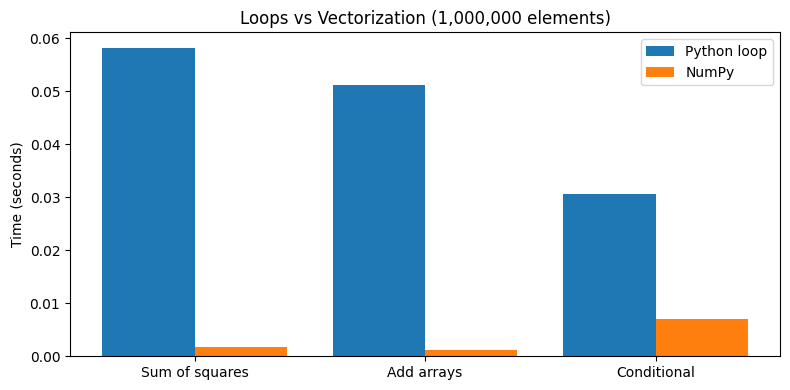

In [48]:
labels = ["Sum of squares", "Add arrays", "Conditional"]
loop_times = [t_loop, t_list, t_a]
numpy_times = [t_np, t_np2, t_b]

x = np.arange(len(labels))
plt.figure(figsize=(8, 4))
plt.bar(x - 0.2, loop_times, 0.4, label="Python loop")
plt.bar(x + 0.2, numpy_times, 0.4, label="NumPy")
plt.xticks(x, labels)
plt.ylabel("Time (seconds)")
plt.title("Loops vs Vectorization (1,000,000 elements)")
plt.legend()
plt.tight_layout()
plt.show()

# Part 5: Practice Projects

## Project 1: Statistical analysis on a dataset
Simulated exam scores for 500 students in 4 subjects.

In [49]:
rng = np.random.default_rng(7)
subjects = ["Math", "Physics", "Chemistry", "English"]
scores = rng.normal(loc=70, scale=12, size=(500, 4)).clip(0, 100).round(1)

print("Shape:", scores.shape)
print("First 3 students:\n", scores[:3])

Shape: (500, 4)
First 3 students:
 [[70.  73.6 66.7 59.3]
 [64.5 58.1 70.7 86.1]
 [64.1 62.6 75.9 74.3]]


In [50]:
# Example 46: per-subject summary
print(f"{'Subject':<10}{'Mean':>8}{'Median':>8}{'Std':>8}{'Min':>7}{'Max':>7}")
for i, name in enumerate(subjects):
    col = scores[:, i]
    print(f"{name:<10}{col.mean():>8.1f}{np.median(col):>8.1f}"
          f"{col.std():>8.1f}{col.min():>7.1f}{col.max():>7.1f}")

Subject       Mean  Median     Std    Min    Max
Math          70.3    69.7    11.7   38.1  100.0
Physics       69.1    68.8    11.8   38.6  100.0
Chemistry     70.1    69.5    11.5   31.0  100.0
English       68.5    68.7    12.1   36.2  100.0


In [51]:
# Example 47: student totals, ranking, top 5
totals = scores.sum(axis=1)
top5 = np.argsort(totals)[::-1][:5]
print("Top 5 student IDs:", top5)
print("Their totals     :", totals[top5])

Top 5 student IDs: [186 225 286 349 166]
Their totals     : [350.3 343.1 339.4 335.1 334.3]


In [52]:
# Example 48: pass/fail analysis (pass mark = 50 in every subject)
passed_all = (scores >= 50).all(axis=1)
print("Passed all subjects:", passed_all.sum(), "of", len(scores))
print("Pass rate per subject (%):", ((scores >= 50).mean(axis=0) * 100).round(1))

Passed all subjects: 409 of 500
Pass rate per subject (%): [96.2 94.6 95.6 94.2]


In [53]:
# Example 49: grade distribution with np.where + np.unique
avg = scores.mean(axis=1)
grades = np.where(avg >= 80, "A",
         np.where(avg >= 70, "B",
         np.where(avg >= 60, "C", "D")))
g, c = np.unique(grades, return_counts=True)
print(dict(zip(g, c)))

{np.str_('A'): np.int64(23), np.str_('B'): np.int64(202), np.str_('C'): np.int64(241), np.str_('D'): np.int64(34)}


In [54]:
# Example 50: correlation matrix between subjects
print(np.corrcoef(scores.T).round(2))

[[1.   0.08 0.08 0.06]
 [0.08 1.   0.07 0.01]
 [0.08 0.07 1.   0.01]
 [0.06 0.01 0.01 1.  ]]


In [55]:
# Example 51: outliers using z-score (|z| > 2.5)
z = (scores - scores.mean(axis=0)) / scores.std(axis=0)
print("Outlier values found:", (np.abs(z) > 2.5).sum())

Outlier values found: 25


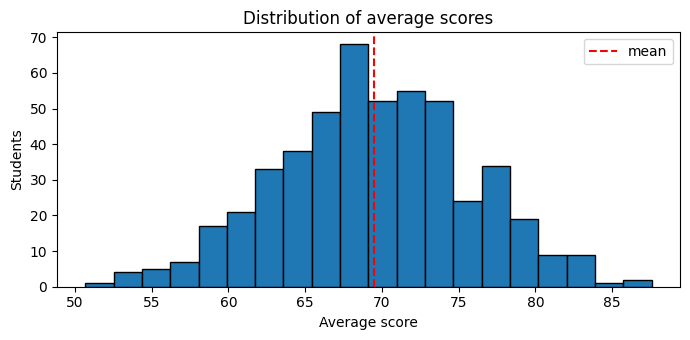

In [56]:
plt.figure(figsize=(7, 3.5))
plt.hist(avg, bins=20, edgecolor="black")
plt.axvline(avg.mean(), color="red", linestyle="--", label="mean")
plt.title("Distribution of average scores")
plt.xlabel("Average score"); plt.ylabel("Students"); plt.legend()
plt.tight_layout(); plt.show()

## Project 2: Data transformation pipeline
Clean, scale and summarise a raw dataset using only NumPy.

In [57]:
# Raw data with missing values (NaN) and an impossible value
raw = np.array([
    [25, 50000, 3.5],
    [32, np.nan, 4.1],
    [47, 90000, np.nan],
    [29, 48000, 3.9],
    [-5, 61000, 4.4],     # invalid age
    [51, 120000, 4.8],
])
print(raw)

[[ 2.5e+01  5.0e+04  3.5e+00]
 [ 3.2e+01      nan  4.1e+00]
 [ 4.7e+01  9.0e+04      nan]
 [ 2.9e+01  4.8e+04  3.9e+00]
 [-5.0e+00  6.1e+04  4.4e+00]
 [ 5.1e+01  1.2e+05  4.8e+00]]


In [58]:
# Example 52: step 1 - remove invalid rows (negative age)
step1 = raw[raw[:, 0] > 0]
print(step1.shape)

(5, 3)


In [59]:
# Example 53: step 2 - fill NaN with the column mean
step2 = step1.copy()
col_means = np.nanmean(step2, axis=0)
nan_rows, nan_cols = np.where(np.isnan(step2))
step2[nan_rows, nan_cols] = col_means[nan_cols]
print(step2.round(1))

[[2.5e+01 5.0e+04 3.5e+00]
 [3.2e+01 7.7e+04 4.1e+00]
 [4.7e+01 9.0e+04 4.1e+00]
 [2.9e+01 4.8e+04 3.9e+00]
 [5.1e+01 1.2e+05 4.8e+00]]


In [60]:
# Example 54: step 3 - min-max scale every column to 0..1
mn, mx = step2.min(axis=0), step2.max(axis=0)
minmax = (step2 - mn) / (mx - mn)
print(minmax.round(2))

[[0.   0.03 0.  ]
 [0.27 0.4  0.46]
 [0.85 0.58 0.44]
 [0.15 0.   0.31]
 [1.   1.   1.  ]]


In [61]:
# Example 55: step 4 - standardize (z-score): mean 0, std 1
standard = (step2 - step2.mean(axis=0)) / step2.std(axis=0)
print("means:", standard.mean(axis=0).round(6))
print("stds :", standard.std(axis=0).round(6))

means: [ 0.  0. -0.]
stds : [1. 1. 1.]


In [62]:
# Example 56: the whole pipeline as one reusable function
def clean_pipeline(data):
    data = data[data[:, 0] > 0]                              # drop invalid
    means = np.nanmean(data, axis=0)
    data = np.where(np.isnan(data), means, data)             # fill NaN
    return (data - data.min(axis=0)) / (data.max(axis=0) - data.min(axis=0))

print(clean_pipeline(raw).round(2))

[[0.   0.03 0.  ]
 [0.27 0.4  0.46]
 [0.85 0.58 0.44]
 [0.15 0.   0.31]
 [1.   1.   1.  ]]


## Project 3: Performance comparison (matrix and statistics)

In [63]:
# Example 57: mean and std - manual loop vs NumPy on 1M values
data = np.random.default_rng(1).normal(50, 10, 1_000_000)
data_list = data.tolist()

def manual_stats():
    n = len(data_list)
    mean = sum(data_list) / n
    var = sum((x - mean) ** 2 for x in data_list) / n
    return mean, var ** 0.5

t1 = timeit(manual_stats)
t2 = timeit(lambda: (data.mean(), data.std()))
print(f"Manual: {t1:.4f} s | NumPy: {t2:.5f} s | speedup: {t1 / t2:.0f}x")

Manual: 0.1476 s | NumPy: 0.00240 s | speedup: 62x


In [64]:
# Example 58: matrix multiplication 200x200 - triple loop vs np.dot
size = 200
A = np.random.default_rng(2).random((size, size))
B = np.random.default_rng(3).random((size, size))

def matmul_loop():
    C = [[0.0] * size for _ in range(size)]
    Al, Bl = A.tolist(), B.tolist()
    for i in range(size):
        for j in range(size):
            s = 0.0
            for k in range(size):
                s += Al[i][k] * Bl[k][j]
            C[i][j] = s
    return C

t1 = timeit(matmul_loop, runs=1)
t2 = timeit(lambda: A @ B)
print(f"Loops: {t1:.3f} s | NumPy: {t2:.5f} s | speedup: {t1 / t2:.0f}x")

Loops: 0.587 s | NumPy: 0.00040 s | speedup: 1472x


## Project 4: Large dataset operations
10 million sales records handled in memory.

In [65]:
rng = np.random.default_rng(5)
n = 10_000_000
price    = rng.uniform(5, 500, n).astype(np.float32)
quantity = rng.integers(1, 10, n).astype(np.int8)
region   = rng.integers(0, 4, n).astype(np.int8)       # 4 regions

print(f"Memory used: {(price.nbytes + quantity.nbytes + region.nbytes) / 1e6:.0f} MB")

Memory used: 60 MB


In [66]:
# Example 59: revenue and totals for 10M rows
start = time.perf_counter()
revenue = price * quantity
print(f"Total revenue: {revenue.sum():,.0f}")
print(f"Average order: {revenue.mean():.2f}")
print(f"Done in {time.perf_counter() - start:.3f} s")

Total revenue: 12,625,246,208
Average order: 1262.52
Done in 0.039 s


In [67]:
# Example 60: revenue per region with boolean masks
region_names = ["North", "South", "East", "West"]
for r, name in enumerate(region_names):
    mask = region == r
    print(f"{name:<6} orders: {mask.sum():>9,}  revenue: {revenue[mask].sum():>16,.0f}")

North  orders: 2,502,306  revenue:    3,160,460,544


South  orders: 2,501,024  revenue:    3,154,144,768


East   orders: 2,497,696  revenue:    3,155,175,936


West   orders: 2,498,974  revenue:    3,155,465,728


In [68]:
# Example 61: same result in one line with np.bincount
print(np.bincount(region, weights=revenue))

[3.16046054e+09 3.15414478e+09 3.15517587e+09 3.15546576e+09]


In [69]:
# Example 62: big orders (revenue > 3000) and 99th percentile
big = revenue > 3000
print("Big orders:", big.sum())
print("99th percentile revenue:", np.percentile(revenue, 99).round(1))

Big orders: 814557


99th percentile revenue: 4097.8
